# Lab 07 - POS Tagging & Named Entity Recognition

**Name:** Zain Ul Wahaj
**Roll Number:** FA23-BAI-058
**Course:** Natural Language Processing

---

This notebook contains the complete solution to all **9 tasks** of Lab 07.
Each part is solved in its own code cell, directly below the question it answers,
with its output shown underneath.

Coarse and fine-grained part-of-speech tags, context-dependent tagging, entity recognition with `doc.ents`, visualisation with displaCy, and extending a pretrained model with an `EntityRuler`. Text files are written to `data/` by Task 01 so the notebook is self-contained.

### Contents

1. **Task 01** - The spaCy pipeline and the news paragraph
2. **Task 02** - Coarse versus fine-grained POS tags
3. **Task 03** - Context-dependent tagging
4. **Task 04** - Filtering noise tokens
5. **Task 05** - Named Entity Recognition with doc.ents
6. **Task 06** - Visualising entities with displaCy
7. **Task 07** - Extending coverage with EntityRuler
8. **Task 08** - Job postings: POS analysis
9. **Task 09** - Job postings: NER and structured extraction

In [1]:
# Zain Ul Wahaj | FA23-BAI-058
# Natural Language Processing - Lab 07 - POS Tagging & Named Entity Recognition

NAME = "Zain Ul Wahaj"
ROLL_NUMBER = "FA23-BAI-058"

print("Name        :", NAME)
print("Roll Number :", ROLL_NUMBER)
print("Course      :", "Natural Language Processing")
print("Lab         :", "Lab 07 - POS Tagging & Named Entity Recognition")

import os
import csv
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt

import spacy
from spacy import displacy

%matplotlib inline
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["figure.dpi"] = 110

os.makedirs("data", exist_ok=True)
print("\nspaCy version:", spacy.__version__)

Name        : Zain Ul Wahaj
Roll Number : FA23-BAI-058
Course      : Natural Language Processing
Lab         : Lab 07 - POS Tagging & Named Entity Recognition



spaCy version: 3.7.5


---

## Task 01: The spaCy pipeline and the news paragraph

### Task 01 (1)

> Load the en_core_web_sm model, write the news paragraph to data/news_paragraph.txt and read it back.

In [2]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (1)
# en_core_web_sm is the small English pipeline: tokenizer, tagger, parser, lemmatizer
# and a statistical NER component, all trained on web text.
nlp = spacy.load("en_core_web_sm")

news_paragraph = (
    "Nasir Electronics said on Tuesday that it would ship to over 40 countries by "
    "March 2027. The company, based in Karachi, raised 12 million dollars last year "
    "and plans to launch a new tablet in Lahore this spring. The launch is expected "
    "to add roughly 15 percent to annual revenue. Chief executive Amina Rao told "
    "Reuters that the Pixel 10 and the iPhone remain the main competitors, and that "
    "Nasir will ship units from a new plant near Islamabad before the end of 2027."
)

with open("data/news_paragraph.txt", "w", encoding="utf-8") as f:
    f.write(news_paragraph)

with open("data/news_paragraph.txt", "r", encoding="utf-8") as f:
    text = f.read()

print("wrote data/news_paragraph.txt")
print("characters:", len(text))
print()
print("pipeline components:")
for name, component in nlp.pipeline:
    print(f"   {name:<16}{type(component).__name__}")

wrote data/news_paragraph.txt
characters: 467

pipeline components:
   tok2vec         Tok2Vec
   tagger          Tagger
   parser          DependencyParser
   attribute_ruler AttributeRuler
   lemmatizer      EnglishLemmatizer
   ner             EntityRecognizer


### Task 01 (2)

> Process the paragraph and report the token and sentence counts.

In [3]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (2)
doc = nlp(text)

print("tokens        :", len(doc))
print("sentences     :", len(list(doc.sents)))
print("entities      :", len(doc.ents))
print("unique lemmas :", len({t.lemma_.lower() for t in doc if t.is_alpha}))
print()
for i, sent in enumerate(doc.sents, 1):
    print(f"{i}. {sent.text.strip()}")

tokens        : 91
sentences     : 4
entities      : 18
unique lemmas : 60

1. Nasir Electronics said on Tuesday that it would ship to over 40 countries by March 2027.
2. The company, based in Karachi, raised 12 million dollars last year and plans to launch a new tablet in Lahore this spring.
3. The launch is expected to add roughly 15 percent to annual revenue.
4. Chief executive Amina Rao told Reuters that the Pixel 10 and the iPhone remain the main competitors, and that Nasir will ship units from a new plant near Islamabad before the end of 2027.


### Task 01 (3)

> Print each token alongside its coarse-grained .pos_ tag and its fine-grained .tag_ tag.

In [4]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (3)
print(f"{'Text':<15} | {'POS':<10} | {'TAG':<6} | {'Explanation of TAG'}")
print("-" * 78)
for token in doc:
    if token.pos_ == "SPACE":
        continue
    print(f"{token.text:<15} | {token.pos_:<10} | {token.tag_:<6} | "
          f"{spacy.explain(token.tag_) or ''}")

Text            | POS        | TAG    | Explanation of TAG
------------------------------------------------------------------------------
Nasir           | PROPN      | NNP    | noun, proper singular
Electronics     | PROPN      | NNP    | noun, proper singular
said            | VERB       | VBD    | verb, past tense
on              | ADP        | IN     | conjunction, subordinating or preposition
Tuesday         | PROPN      | NNP    | noun, proper singular
that            | SCONJ      | IN     | conjunction, subordinating or preposition
it              | PRON       | PRP    | pronoun, personal
would           | AUX        | MD     | verb, modal auxiliary
ship            | VERB       | VB     | verb, base form
to              | ADP        | IN     | conjunction, subordinating or preposition
over            | ADP        | IN     | conjunction, subordinating or preposition
40              | NUM        | CD     | cardinal number
countries       | NOUN       | NNS    | noun, plural
by    

### Task 01 (4)

> Identify one word whose tag differs from what you would expect from its most common usage.

In [5]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 01 (4)
# "ship" is far more often a noun in everyday English, but here it heads a verb phrase
# ("would ship to over 40 countries"), so the tagger reads it from context.
for target in ("ship", "launch", "plant"):
    hits = [t for t in doc if t.text.lower() == target]
    if not hits:
        continue
    print(f"'{target}':")
    for t in hits:
        start, end = max(0, t.i - 3), min(len(doc), t.i + 4)
        print(f"   {t.pos_:<6} ({t.tag_:<4}) ... {doc[start:end].text.strip()} ...")
    print()

print("'ship' is a noun in its most common usage, but both occurrences here are VERB.")
print("'plant' is tagged NOUN, which is the reading a frequency table would also give,")
print("but the tagger reaches it from the surrounding words rather than from a lookup.")

'ship':
   VERB   (VB  ) ... that it would ship to over 40 ...
   VERB   (VB  ) ... that Nasir will ship units from a ...

'launch':
   VERB   (VB  ) ... and plans to launch a new tablet ...
   NOUN   (NN  ) ... spring. The launch is expected to ...

'plant':
   NOUN   (NN  ) ... from a new plant near Islamabad before ...

'ship' is a noun in its most common usage, but both occurrences here are VERB.
'plant' is tagged NOUN, which is the reading a frequency table would also give,
but the tagger reaches it from the surrounding words rather than from a lookup.


---

## Task 02: Coarse versus fine-grained POS tags

### Task 02 (1)

> Explain the difference between .pos_ and .tag_ using spacy.explain().

In [6]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (1)
# .pos_ is the Universal POS tag: a small, language-independent set (~17 tags).
# .tag_ is the fine-grained treebank tag, which for English is the Penn Treebank set
# and encodes tense, number and degree on top of the word class.
samples = ["said", "countries", "new", "would", "roughly"]
print(f"{'token':<12}{'pos_':<8}{'UPOS means':<28}{'tag_':<7}{'PTB means'}")
print("-" * 95)
for t in doc:
    if t.text.lower() in samples:
        print(f"{t.text:<12}{t.pos_:<8}{str(spacy.explain(t.pos_)):<28}"
              f"{t.tag_:<7}{spacy.explain(t.tag_)}")
        samples.remove(t.text.lower())

token       pos_    UPOS means                  tag_   PTB means
-----------------------------------------------------------------------------------------------
said        VERB    verb                        VBD    verb, past tense
would       AUX     auxiliary                   MD     verb, modal auxiliary
countries   NOUN    noun                        NNS    noun, plural
new         ADJ     adjective                   JJ     adjective (English), other noun-modifier (Chinese)
roughly     ADV     adverb                      RB     adverb


### Task 02 (2)

> Show which fine-grained tags appear under each coarse tag in this paragraph.

In [7]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (2)
grouped = defaultdict(Counter)
for t in doc:
    if t.pos_ != "SPACE":
        grouped[t.pos_][t.tag_] += 1

print(f"{'POS':<8}{'fine-grained tags seen under it'}")
print("-" * 60)
for pos in sorted(grouped):
    detail = ", ".join(f"{tag} x{n}" for tag, n in grouped[pos].most_common())
    print(f"{pos:<8}{detail}")

split = {p: g for p, g in grouped.items() if len(g) > 1}
print(f"\n{len(split)} coarse tags split into more than one fine tag: {sorted(split)}")
print("That split is the information .tag_ adds - VERB alone does not tell you tense.")

POS     fine-grained tags seen under it
------------------------------------------------------------
ADJ     JJ x6
ADP     IN x11
ADV     RB x1
AUX     MD x2, VBZ x1
CCONJ   CC x3
DET     DT x9
NOUN    NN x10, NNS x4
NUM     CD x7
PART    TO x2
PRON    PRP x1
PROPN   NNP x13
PUNCT   . x4, , x3
SCONJ   IN x3
VERB    VB x4, VBD x3, VBN x2, VBZ x1, VBP x1

4 coarse tags split into more than one fine tag: ['AUX', 'NOUN', 'PUNCT', 'VERB']
That split is the information .tag_ adds - VERB alone does not tell you tense.


### Task 02 (3)

> Plot the frequency of each coarse POS tag.

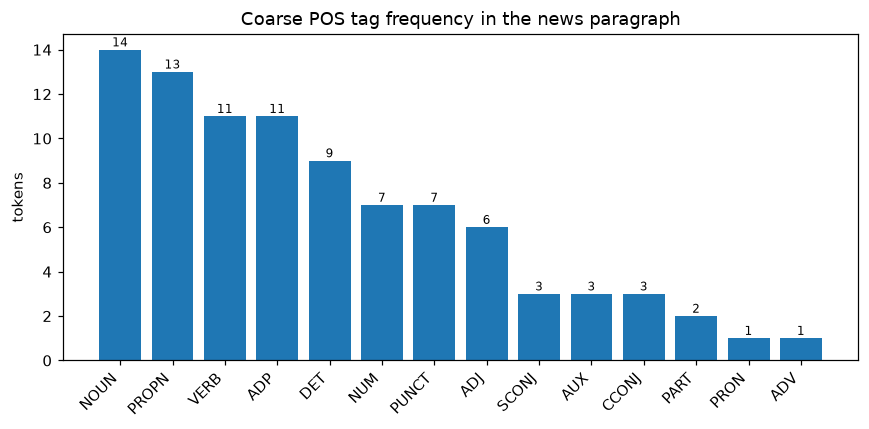

tag       count  meaning
NOUN         14  noun
PROPN        13  proper noun
VERB         11  verb
ADP          11  adposition
DET           9  determiner
NUM           7  numeral
PUNCT         7  punctuation
ADJ           6  adjective
SCONJ         3  subordinating conjunction
AUX           3  auxiliary
CCONJ         3  coordinating conjunction
PART          2  particle
PRON          1  pronoun
ADV           1  adverb


In [8]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (3)
pos_counts = Counter(t.pos_ for t in doc if t.pos_ != "SPACE")
labels, values = zip(*pos_counts.most_common())

plt.figure(figsize=(8, 4))
plt.bar(labels, values, color="tab:blue")
plt.ylabel("tokens")
plt.title("Coarse POS tag frequency in the news paragraph")
plt.xticks(rotation=45, ha="right")
for i, v in enumerate(values):
    plt.text(i, v + 0.15, str(v), ha="center", fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'tag':<8}{'count':>7}  {'meaning'}")
for tag, n in pos_counts.most_common():
    print(f"{tag:<8}{n:>7}  {spacy.explain(tag)}")

### Task 02 (4)

> Demonstrate a case where the coarse tag is identical but the fine tag differs.

In [9]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 02 (4)
by_pos = defaultdict(list)
for t in doc:
    by_pos[t.pos_].append(t)

for pos in ("VERB", "NOUN", "ADJ"):
    tags = {t.tag_: t for t in by_pos.get(pos, [])}
    if len(tags) > 1:
        print(f"{pos} tokens carrying different fine tags:")
        for tag, t in tags.items():
            print(f"   {t.text:<12} {pos:<6} {tag:<5} {spacy.explain(tag)}")
        print()

print("Two words can share a coarse tag and still differ grammatically. A downstream")
print("step that needs tense or plurality has to read .tag_; one that only needs the")
print("word class can stay on .pos_ and keep working across languages.")

VERB tokens carrying different fine tags:
   told         VERB   VBD   verb, past tense
   ship         VERB   VB    verb, base form
   expected     VERB   VBN   verb, past participle
   plans        VERB   VBZ   verb, 3rd person singular present
   remain       VERB   VBP   verb, non-3rd person singular present

NOUN tokens carrying different fine tags:
   units        NOUN   NNS   noun, plural
   end          NOUN   NN    noun, singular or mass

Two words can share a coarse tag and still differ grammatically. A downstream
step that needs tense or plurality has to read .tag_; one that only needs the
word class can stay on .pos_ and keep working across languages.


---

## Task 03: Context-dependent tagging

### Task 03 (1)

> Find every word in the paragraph that appears more than once with a different .pos_ tag.

In [10]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (1)
seen = defaultdict(set)
for t in doc:
    if t.is_alpha:
        seen[t.text.lower()].add(t.pos_)

ambiguous = {w: tags for w, tags in seen.items() if len(tags) > 1}
print("words tagged differently in different places:")
for w, tags in sorted(ambiguous.items()):
    print(f"   {w:<12}{sorted(tags)}")

if not ambiguous:
    print("   (none in this paragraph)")

words tagged differently in different places:
   launch      ['NOUN', 'VERB']
   to          ['ADP', 'PART']


### Task 03 (2)

> Show both occurrences of one such word with its surrounding context and its .pos_ tag.

In [11]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (2)
target_word = "launch"
print(f"Context-dependent tagging for the word '{target_word}':\n")

for token in doc:
    if token.text.lower() == target_word:
        # Print the surrounding context for clarity
        start = max(0, token.i - 3)
        end = min(len(doc), token.i + 4)
        context = doc[start:end].text
        print(f"Phrase: '... {context.strip()} ...'")
        print(f"Token: {token.text} | POS: {token.pos_} | TAG: {token.tag_}")
        print(f"Head:  {token.head.text} ({token.head.pos_}) | dep: {token.dep_}\n")

Context-dependent tagging for the word 'launch':

Phrase: '... and plans to launch a new tablet ...'
Token: launch | POS: VERB | TAG: VB
Head:  plans (VERB) | dep: xcomp

Phrase: '... spring. The launch is expected to ...'
Token: launch | POS: NOUN | TAG: NN
Head:  expected (VERB) | dep: nsubjpass



### Task 03 (3)

> Write two sentences using the same word in different grammatical roles and tag both.

In [12]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (3)
pairs = [
    ("They will record the album in Karachi next week.", "record"),
    ("She broke the world record at the meet in Lahore.", "record"),
    ("The company will present the results on Friday.", "present"),
    ("He received a present for his birthday.", "present"),
]

print(f"{'word':<10}{'POS':<8}{'TAG':<6}sentence")
print("-" * 78)
for sentence, word in pairs:
    d = nlp(sentence)
    for t in d:
        if t.text.lower() == word:
            print(f"{t.text:<10}{t.pos_:<8}{t.tag_:<6}{sentence}")

word      POS     TAG   sentence
------------------------------------------------------------------------------
record    VERB    VB    They will record the album in Karachi next week.
record    NOUN    NN    She broke the world record at the meet in Lahore.
present   VERB    VB    The company will present the results on Friday.
present   NOUN    NN    He received a present for his birthday.


### Task 03 (4)

> Explain why a dictionary lookup could not produce these tags.

In [13]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 03 (4)
word = "record"
d1 = nlp("They will record the album in Karachi next week.")
d2 = nlp("She broke the world record at the meet in Lahore.")
t1 = [t for t in d1 if t.text.lower() == word][0]
t2 = [t for t in d2 if t.text.lower() == word][0]

print(f"'{word}' after 'will'       -> {t1.pos_} ({t1.tag_}), head '{t1.head.text}'")
print(f"'{word}' after 'the world'  -> {t2.pos_} ({t2.tag_}), head '{t2.head.text}'")
print()
print("The surface string is identical in both sentences, so any table mapping a word")
print("to a single tag has to be wrong in one of the two cases. The tagger instead")
print("reads the neighbouring tokens: a modal verb in front makes a verb reading far")
print("more likely, a determiner and a modifier make a noun reading more likely. That")
print("is why POS tagging is a sequence model rather than a lookup, and it is also why")
print("the tagger can tag a word it has never seen before.")

'record' after 'will'       -> VERB (VB), head 'record'
'record' after 'the world'  -> NOUN (NN), head 'broke'

The surface string is identical in both sentences, so any table mapping a word
to a single tag has to be wrong in one of the two cases. The tagger instead
reads the neighbouring tokens: a modal verb in front makes a verb reading far
more likely, a determiner and a modifier make a noun reading more likely. That
is why POS tagging is a sequence model rather than a lookup, and it is also why
the tagger can tag a word it has never seen before.


---

## Task 04: Filtering noise tokens

### Task 04 (1)

> Count how many tokens fall into the noise categories SPACE, PUNCT and X.

In [14]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (1)
noise_tags = {"SPACE", "PUNCT", "X"}
noise = [t for t in doc if t.pos_ in noise_tags]

print("total tokens:", len(doc))
print("noise tokens:", len(noise))
print()
for tag, n in Counter(t.pos_ for t in noise).most_common():
    examples = [repr(t.text) for t in noise if t.pos_ == tag][:6]
    print(f"   {tag:<7}{n:>4}   e.g. {', '.join(examples)}")

total tokens: 91
noise tokens: 7

   PUNCT     7   e.g. '.', ',', ',', '.', '.', ','


### Task 04 (2)

> Filter out the noise tokens and print a clean table of the meaningful tokens with their POS tags.

In [15]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (2)
noise_tags = {"SPACE", "PUNCT", "X"}
print(f"{'Clean Text':<15} | {'POS'}")
print("-" * 30)
for token in doc:
    if token.pos_ not in noise_tags:
        print(f"{token.text:<15} | {token.pos_}")

Clean Text      | POS
------------------------------
Nasir           | PROPN
Electronics     | PROPN
said            | VERB
on              | ADP
Tuesday         | PROPN
that            | SCONJ
it              | PRON
would           | AUX
ship            | VERB
to              | ADP
over            | ADP
40              | NUM
countries       | NOUN
by              | ADP
March           | PROPN
2027            | NUM
The             | DET
company         | NOUN
based           | VERB
in              | ADP
Karachi         | PROPN
raised          | VERB
12              | NUM
million         | NUM
dollars         | NOUN
last            | ADJ
year            | NOUN
and             | CCONJ
plans           | VERB
to              | PART
launch          | VERB
a               | DET
new             | ADJ
tablet          | NOUN
in              | ADP
Lahore          | PROPN
this            | DET
spring          | NOUN
The             | DET
launch          | NOUN
is              | AUX
expected      

### Task 04 (3)

> Compare the token count before and after filtering, and after also removing stop words.

In [16]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (3)
kept = [t for t in doc if t.pos_ not in noise_tags]
content = [t for t in kept if not t.is_stop and t.is_alpha]

rows = [("all tokens", len(doc)),
        ("minus SPACE/PUNCT/X", len(kept)),
        ("minus stop words and non-alphabetic", len(content))]

for label, n in rows:
    print(f"{label:<38}{n:>5}   ({n / len(doc):>6.1%} of the original)")

print("\nremaining content tokens:")
print("  ", ", ".join(t.text for t in content))

all tokens                               91   (100.0% of the original)
minus SPACE/PUNCT/X                      84   ( 92.3% of the original)
minus stop words and non-alphabetic      46   ( 50.5% of the original)

remaining content tokens:
   Nasir, Electronics, said, Tuesday, ship, countries, March, company, based, Karachi, raised, million, dollars, year, plans, launch, new, tablet, Lahore, spring, launch, expected, add, roughly, percent, annual, revenue, Chief, executive, Amina, Rao, told, Reuters, Pixel, iPhone, remain, main, competitors, Nasir, ship, units, new, plant, near, Islamabad, end


### Task 04 (4)

> Print the most frequent lemmas among the content tokens.

In [17]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 04 (4)
# Lemmatising first means 'countries' and 'country' are counted together, which is
# what you want before any frequency-based step.
lemmas = Counter(t.lemma_.lower() for t in content)

print(f"{'lemma':<14}{'count':>7}   surface forms")
print("-" * 52)
for lemma, n in lemmas.most_common(10):
    forms = sorted({t.text for t in content if t.lemma_.lower() == lemma})
    print(f"{lemma:<14}{n:>7}   {', '.join(forms)}")

lemma           count   surface forms
----------------------------------------------------
nasir               2   Nasir
ship                2   ship
launch              2   launch
new                 2   new
electronics         1   Electronics
say                 1   said
tuesday             1   Tuesday
country             1   countries
march               1   March
company             1   company


---

## Task 05: Named Entity Recognition with doc.ents

### Task 05 (1)

> Extract all named entities from the paragraph using doc.ents.

In [18]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (1)
print(f"{'entity':<22}{'label':<10}{'start':>6}{'end':>6}")
print("-" * 46)
for ent in doc.ents:
    print(f"{ent.text:<22}{ent.label_:<10}{ent.start_char:>6}{ent.end_char:>6}")

print(f"\n{len(doc.ents)} entities found")

entity                label      start   end
----------------------------------------------
Nasir Electronics     ORG            0    17
Tuesday               DATE          26    33
40                    CARDINAL      61    63
March 2027            DATE          77    87
Karachi               GPE          111   118
12 million dollars    MONEY        127   145
last year             DATE         146   155
Lahore                GPE          192   198
this spring           DATE         199   210
roughly 15 percent    PERCENT      242   260
annual                DATE         264   270
Amina Rao             PERSON       296   305
Reuters               ORG          311   318
Pixel                 PERSON       328   333
10                    CARDINAL     334   336
Nasir                 PERSON       390   395
Islamabad             GPE          434   443
the end of 2027       DATE         451   466

18 entities found


### Task 05 (2)

> Use spacy.explain() to describe each entity label that appears.

In [19]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (2)
labels = sorted({ent.label_ for ent in doc.ents})
print(f"{'label':<10}{'meaning':<46}{'examples'}")
print("-" * 92)
for label in labels:
    examples = ", ".join(sorted({e.text for e in doc.ents if e.label_ == label}))
    print(f"{label:<10}{str(spacy.explain(label)):<46}{examples}")

label     meaning                                       examples
--------------------------------------------------------------------------------------------
CARDINAL  Numerals that do not fall under another type  10, 40
DATE      Absolute or relative dates or periods         March 2027, Tuesday, annual, last year, the end of 2027, this spring
GPE       Countries, cities, states                     Islamabad, Karachi, Lahore
MONEY     Monetary values, including unit               12 million dollars
ORG       Companies, agencies, institutions, etc.       Nasir Electronics, Reuters
PERCENT   Percentage, including "%"                     roughly 15 percent
PERSON    People, including fictional                   Amina Rao, Nasir, Pixel


### Task 05 (3)

> Count how many entities fall under each type.

In [20]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (3)
entity_counts = Counter(ent.label_ for ent in doc.ents)

print("Entity Type Counts:")
print("-" * 24)
for ent_type, count in entity_counts.most_common():
    print(f"{ent_type:<10}{count}")

expected = ["PERSON", "ORG", "GPE", "DATE", "MONEY", "PERCENT"]
print("\nagainst the six types the lab asks about:")
for e in expected:
    print(f"   {e:<10}{entity_counts.get(e, 0)}")

Entity Type Counts:
------------------------
DATE      6
GPE       3
PERSON    3
ORG       2
CARDINAL  2
MONEY     1
PERCENT   1

against the six types the lab asks about:
   PERSON    3
   ORG       2
   GPE       3
   DATE      6
   MONEY     1
   PERCENT   1


### Task 05 (4)

> Show the token-level IOB tags to explain how multi-token entities are encoded.

In [21]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 05 (4)
# doc.ents gives spans. Underneath, every token carries an IOB code: B begins an
# entity, I continues one, O is outside. That is how a two-word entity such as
# "Amina Rao" stays a single span rather than two.
print(f"{'token':<16}{'IOB':<5}{'ent_type_'}")
print("-" * 40)
for t in doc:
    if t.ent_iob_ != "O":
        print(f"{t.text:<16}{t.ent_iob_:<5}{t.ent_type_}")

multi = [e for e in doc.ents if len(e) > 1]
print(f"\n{len(multi)} entities span more than one token:")
for e in multi:
    print(f"   {e.text!r} ({len(e)} tokens, {e.label_})")

token           IOB  ent_type_
----------------------------------------
Nasir           B    ORG
Electronics     I    ORG
Tuesday         B    DATE
40              B    CARDINAL
March           B    DATE
2027            I    DATE
Karachi         B    GPE
12              B    MONEY
million         I    MONEY
dollars         I    MONEY
last            B    DATE
year            I    DATE
Lahore          B    GPE
this            B    DATE
spring          I    DATE
roughly         B    PERCENT
15              I    PERCENT
percent         I    PERCENT
annual          B    DATE
Amina           B    PERSON
Rao             I    PERSON
Reuters         B    ORG
Pixel           B    PERSON
10              B    CARDINAL
Nasir           B    PERSON
Islamabad       B    GPE
the             B    DATE
end             I    DATE
of              I    DATE
2027            I    DATE

8 entities span more than one token:
   'Nasir Electronics' (2 tokens, ORG)
   'March 2027' (2 tokens, DATE)
   '12 million d

---

## Task 06: Visualising entities with displaCy

### Task 06 (1)

> Visualize the entities in the paragraph using displaCy.

In [22]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (1)
# Visualize entities directly in the notebook output
displacy.render(doc, style="ent", jupyter=True)

### Task 06 (2)

> Plot the entity type counts as a bar chart.

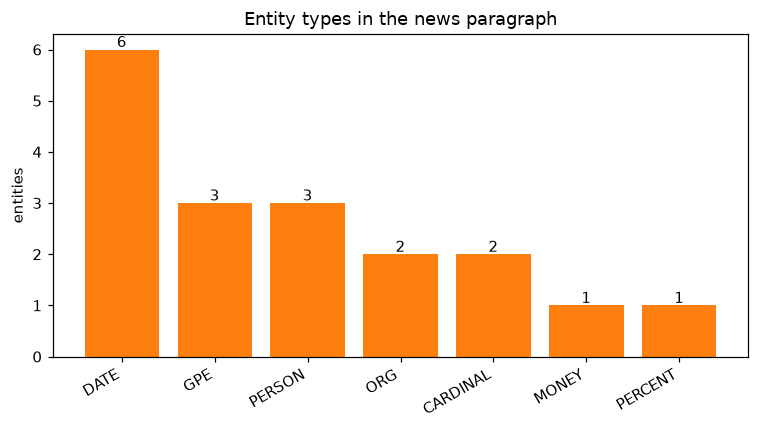

In [23]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (2)
labels, values = zip(*entity_counts.most_common())

plt.figure(figsize=(7, 4))
plt.bar(labels, values, color="tab:orange")
plt.ylabel("entities")
plt.title("Entity types in the news paragraph")
plt.xticks(rotation=30, ha="right")
for i, v in enumerate(values):
    plt.text(i, v + 0.05, str(v), ha="center")
plt.tight_layout()
plt.show()

### Task 06 (3)

> Render the dependency parse of one sentence with displaCy.

In [24]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (3)
first_sentence = list(doc.sents)[0]
print(first_sentence.text.strip(), "\n")
displacy.render(first_sentence, style="dep", jupyter=True,
                options={"compact": True, "distance": 95})

Nasir Electronics said on Tuesday that it would ship to over 40 countries by March 2027. 



### Task 06 (4)

> Render the entity visualisation to an HTML string and save it to a file.

In [25]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 06 (4)
# jupyter=False returns the markup instead of displaying it, which is how you would
# embed the visualisation in a report or a web page.
html = displacy.render(doc, style="ent", jupyter=False)

with open("data/entities.html", "w", encoding="utf-8") as f:
    f.write(html)

print("wrote data/entities.html")
print("html length:", len(html), "characters")
print("\nfirst 300 characters:")
print(html[:300])

wrote data/entities.html
html length: 5859 characters

first 300 characters:
<div class="entities" style="line-height: 2.5; direction: ltr">
<mark class="entity" style="background: #7aecec; padding: 0.45em 0.6em; margin: 0 0.25em; line-height: 1; border-radius: 0.35em;">
    Nasir Electronics
    <span style="font-size: 0.8em; font-weight: bold; line-height: 1; border-radius


---

## Task 07: Extending coverage with EntityRuler

### Task 07 (1)

> Identify an entity in the paragraph that the pretrained model misses or misclassifies.

In [26]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (1)
product_terms = ["Pixel 10", "iPhone"]
found = {e.text: e.label_ for e in doc.ents}

print("How the default model handles the product names:")
for term in product_terms:
    hit = [lbl for txt, lbl in found.items() if term in txt or txt in term]
    print(f"   {term:<12} -> {hit if hit else 'NOT TAGGED AS AN ENTITY'}")

print(f"\nPRODUCT entities found by the default model: "
      f"{[e.text for e in doc.ents if e.label_ == 'PRODUCT'] or 'none'}")
print("\nThe model was trained on general web text, so a specific device name that")
print("post-dates its training data is either missed or absorbed into another type.")

How the default model handles the product names:
   Pixel 10     -> ['PERSON', 'CARDINAL']
   iPhone       -> NOT TAGGED AS AN ENTITY

PRODUCT entities found by the default model: none

The model was trained on general web text, so a specific device name that
post-dates its training data is either missed or absorbed into another type.


### Task 07 (2)

> Add a custom EntityRuler pattern to capture it correctly.

In [27]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (2)
# A fresh pipeline, with the ruler inserted BEFORE the statistical ner component so
# its matches are already in place when ner runs.
nlp_custom = spacy.load("en_core_web_sm")
ruler = nlp_custom.add_pipe("entity_ruler", before="ner")

patterns = [
    {"label": "PRODUCT", "pattern": "Pixel 10"},
    {"label": "PRODUCT", "pattern": "iPhone"},
]
ruler.add_patterns(patterns)

print("pipeline after adding the ruler:")
for name, _ in nlp_custom.pipeline:
    marker = "  <-- added" if name == "entity_ruler" else ""
    print(f"   {name}{marker}")

pipeline after adding the ruler:
   tok2vec
   tagger
   parser
   attribute_ruler
   lemmatizer
   entity_ruler  <-- added
   ner


### Task 07 (3)

> Re-run NER on the paragraph and verify the fix.

In [28]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (3)
doc_updated = nlp_custom(text)

print("Verified Custom Entities:")
print("-" * 32)
for ent in doc_updated.ents:
    if ent.label_ == "PRODUCT":
        print(f"Text: {ent.text:<15} | Label: {ent.label_}")

before = {(e.text, e.label_) for e in doc.ents}
after = {(e.text, e.label_) for e in doc_updated.ents}

print("\nnewly recognised:")
for item in sorted(after - before):
    print("   +", item)
print("no longer recognised:")
for item in sorted(before - after):
    print("   -", item)

Verified Custom Entities:
--------------------------------
Text: Pixel 10        | Label: PRODUCT
Text: iPhone          | Label: PRODUCT

newly recognised:
   + ('Pixel 10', 'PRODUCT')
   + ('iPhone', 'PRODUCT')
no longer recognised:
   - ('10', 'CARDINAL')
   - ('Pixel', 'PERSON')


### Task 07 (4)

> Show what changes if the ruler runs after the NER component instead of before.

In [29]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 07 (4)
nlp_after = spacy.load("en_core_web_sm")
ruler_after = nlp_after.add_pipe("entity_ruler", after="ner")
ruler_after.add_patterns(patterns)
doc_after = nlp_after(text)

print(f"{'placement':<22}{'PRODUCT entities found'}")
print("-" * 60)
for label, d in [("before='ner'", doc_updated), ("after='ner'", doc_after)]:
    prods = [e.text for e in d.ents if e.label_ == "PRODUCT"]
    print(f"{label:<22}{prods}")

print()
print("spaCy does not allow entity spans to overlap. Placed before ner, the ruler")
print("claims its spans first and the statistical model has to work around them.")
print("Placed after, the ruler can only add entities in positions ner left free, so a")
print("term the model already tagged as something else keeps the model's label.")
print("Before is the right choice when your patterns are domain knowledge the model")
print("does not have; after is right when you only want to fill in the gaps.")

placement             PRODUCT entities found
------------------------------------------------------------
before='ner'          ['Pixel 10', 'iPhone']
after='ner'           ['iPhone']

spaCy does not allow entity spans to overlap. Placed before ner, the ruler
claims its spans first and the statistical model has to work around them.
Placed after, the ruler can only add entities in positions ner left free, so a
term the model already tagged as something else keeps the model's label.
Before is the right choice when your patterns are domain knowledge the model
does not have; after is right when you only want to fill in the gaps.


---

## Task 08: Job postings: POS analysis

### Task 08 (1)

> Write the job postings dataset to data/job_postings.csv and load it.

In [30]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (1)
postings = [
    "Systems Limited is hiring a Backend Engineer in Lahore. You will design REST APIs "
    "in Python, deploy services to AWS, and record deployment runbooks for the team.",
    "Careem is looking for a Product Designer based in Karachi. Candidates should "
    "present a portfolio built in Figma and be comfortable running user research.",
    "NetSol Technologies seeks a Data Analyst in Islamabad. The role covers SQL, Python "
    "and building dashboards in Power BI for a present client base of 40 companies.",
    "Folio3 is recruiting a Machine Learning Engineer in Karachi. You will train models "
    "in PyTorch, ship features to production weekly, and present findings to clients.",
    "Arbisoft needs a DevOps Engineer in Lahore. Experience with AWS, Docker and "
    "Kubernetes is required, and you will record infrastructure changes as code.",
    "Tkxel is hiring a Frontend Engineer in Lahore to build React interfaces, work "
    "with designers in Figma, and ship releases every sprint.",
    "Afiniti is looking for a Research Scientist in Karachi. You will design "
    "experiments, analyse results in Python, and publish a yearly research record.",
    "Contour Software is hiring a QA Engineer in Islamabad to write automated tests in "
    "Python, record defects clearly, and verify each AWS deployment before release.",
]

with open("data/job_postings.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["posting_id", "text"])
    w.writeheader()
    for i, p in enumerate(postings, 1):
        w.writerow({"posting_id": f"JP{i:02d}", "text": p})

jobs = pd.read_csv("data/job_postings.csv")
print("wrote data/job_postings.csv, shape:", jobs.shape)
print()
for _, r in jobs.head(3).iterrows():
    print(f"{r.posting_id}: {r.text[:95]}...")

wrote data/job_postings.csv, shape: (8, 2)

JP01: Systems Limited is hiring a Backend Engineer in Lahore. You will design REST APIs in Python, de...
JP02: Careem is looking for a Product Designer based in Karachi. Candidates should present a portfoli...
JP03: NetSol Technologies seeks a Data Analyst in Islamabad. The role covers SQL, Python and building...


### Task 08 (2)

> Extract and tabulate POS tags across the full job postings text.

In [31]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (2)
job_docs = {r.posting_id: nlp(r.text) for _, r in jobs.iterrows()}

rows = []
for pid, d in job_docs.items():
    counts = Counter(t.pos_ for t in d if t.pos_ not in noise_tags)
    rows.append({"posting_id": pid, "tokens": sum(counts.values()), **counts})

pos_table = pd.DataFrame(rows).set_index("posting_id").fillna(0).astype(int)
print(pos_table[["tokens", "NOUN", "VERB", "PROPN", "ADJ", "ADP", "DET"]])

print("\ntotals across all postings:")
total = Counter()
for d in job_docs.values():
    total.update(t.pos_ for t in d if t.pos_ not in noise_tags)
for tag, n in total.most_common(8):
    print(f"   {tag:<7}{n:>5}   {spacy.explain(tag)}")

            tokens  NOUN  VERB  PROPN  ADJ  ADP  DET
posting_id                                          
JP01            27     7     3      7    0    4    2
JP02            24     4     5      5    1    3    2
JP03            27     5     3      9    1    4    3
JP04            25     7     2      6    1    4    1
JP05            23     4     3      7    0    3    1
JP06            22     4     4      6    0    3    2
JP07            23     4     3      5    1    3    2
JP08            25     5     4      7    0    3    2

totals across all postings:
   PROPN     52   proper noun
   NOUN      40   noun
   VERB      27   verb
   ADP       27   adposition
   DET       15   determiner
   AUX       13   auxiliary
   CCONJ      9   coordinating conjunction
   PRON       4   pronoun


### Task 08 (3)

> Report the 5 most frequent nouns and the 5 most frequent verbs across all postings combined.

In [32]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (3)
nouns = Counter()
verbs = Counter()
for d in job_docs.values():
    for t in d:
        if t.pos_ == "NOUN":
            nouns[t.lemma_.lower()] += 1
        elif t.pos_ == "VERB":
            verbs[t.lemma_.lower()] += 1

print("5 most frequent NOUNS (lemmatised):")
for lemma, n in nouns.most_common(5):
    print(f"   {lemma:<16}{n}")

print("\n5 most frequent VERBS (lemmatised):")
for lemma, n in verbs.most_common(5):
    print(f"   {lemma:<16}{n}")

print("\nPROPN is counted separately from NOUN, so company and city names do not")
print("crowd out the ordinary nouns that describe the role.")

5 most frequent NOUNS (lemmatised):
   record          3
   deployment      2
   research        2
   client          2
   ship            2

5 most frequent VERBS (lemmatised):
   hire            3
   build           3
   design          2
   look            2
   deploy          1

PROPN is counted separately from NOUN, so company and city names do not
crowd out the ordinary nouns that describe the role.


### Task 08 (4)

> Find a word whose POS tag changes across different postings and show both occurrences with their tags.

In [33]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 08 (4)
occurrences = defaultdict(list)
for pid, d in job_docs.items():
    for t in d:
        if t.is_alpha and not t.is_stop:
            occurrences[t.text.lower()].append((pid, t))

changing = {w: occ for w, occ in occurrences.items()
            if len({t.pos_ for _, t in occ}) > 1}

for word, occ in sorted(changing.items()):
    print(f"'{word}' is tagged differently across postings:")
    shown = set()
    for pid, t in occ:
        if t.pos_ in shown:
            continue
        shown.add(t.pos_)
        start, end = max(0, t.i - 4), min(len(t.doc), t.i + 5)
        print(f"   {pid}  {t.pos_:<6} ({t.tag_:<4}) ... {t.doc[start:end].text.strip()} ...")
    print()

if not changing:
    print("No word changes its coarse tag across these postings.")

'present' is tagged differently across postings:
   JP02  VERB   (VB  ) ... Karachi. Candidates should present a portfolio built in ...
   JP03  ADJ    (JJ  ) ... Power BI for a present client base of 40 ...

'record' is tagged differently across postings:
   JP01  NOUN   (NN  ) ... to AWS, and record deployment runbooks for the ...
   JP05  VERB   (VB  ) ... , and you will record infrastructure changes as code ...

'research' is tagged differently across postings:
   JP02  NOUN   (NN  ) ... be comfortable running user research. ...
   JP07  PROPN  (NNP ) ... is looking for a Research Scientist in Karachi. ...



---

## Task 09: Job postings: NER and structured extraction

### Task 09 (1)

> Extract named entities from all postings, group them by type and report the count for each. Note which type appears most often and why.

In [34]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (1)
by_type = defaultdict(Counter)
for pid, d in job_docs.items():
    for e in d.ents:
        by_type[e.label_][e.text] += 1

print(f"{'label':<10}{'total':>7}   entities")
print("-" * 84)
for label in sorted(by_type, key=lambda l: -sum(by_type[l].values())):
    total_n = sum(by_type[label].values())
    items = ", ".join(f"{t} x{n}" if n > 1 else t
                      for t, n in by_type[label].most_common())
    print(f"{label:<10}{total_n:>7}   {items[:66]}")

top = max(by_type, key=lambda l: sum(by_type[l].values()))
print(f"\nMost frequent type: {top} ({sum(by_type[top].values())} mentions)")
print("That fits job postings: every posting names the hiring company and the city it")
print("is based in, so organisation and place names appear once or more in each row,")
print("while types such as MONEY or PERCENT barely feature at all.")

label       total   entities
------------------------------------------------------------------------------------
ORG            13   AWS x2, Figma x2, NetSol Technologies, SQL, Power BI, Machine Lear
GPE            10   Lahore x3, Karachi x3, Islamabad x2, Python x2
PERSON          2   Docker, Contour Software
CARDINAL        1   40
DATE            1   weekly

Most frequent type: ORG (13 mentions)
That fits job postings: every posting names the hiring company and the city it
is based in, so organisation and place names appear once or more in each row,
while types such as MONEY or PERCENT barely feature at all.


### Task 09 (2)

> Add a custom EntityRuler for the skill keywords that the default model does not tag.

In [35]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (2)
SKILLS = ["Python", "AWS", "Figma", "SQL", "Docker", "Kubernetes", "React",
          "PyTorch", "Power BI", "REST APIs"]

default_hits = set()
for d in job_docs.values():
    for e in d.ents:
        default_hits.add(e.text)

print("how the default model treats the skill terms:")
for s in SKILLS:
    tagged = [e.label_ for d in job_docs.values() for e in d.ents if e.text == s]
    print(f"   {s:<12} -> {tagged if tagged else 'not an entity'}")

nlp_skills = spacy.load("en_core_web_sm")
skill_ruler = nlp_skills.add_pipe("entity_ruler", before="ner")
skill_ruler.add_patterns([{"label": "SKILL", "pattern": s} for s in SKILLS])
print(f"\nadded {len(SKILLS)} SKILL patterns before the ner component")

how the default model treats the skill terms:
   Python       -> ['GPE', 'GPE']
   AWS          -> ['ORG', 'ORG']
   Figma        -> ['ORG', 'ORG']
   SQL          -> ['ORG']
   Docker       -> ['PERSON']
   Kubernetes   -> ['ORG']
   React        -> not an entity
   PyTorch      -> ['ORG']
   Power BI     -> ['ORG']
   REST APIs    -> not an entity



added 10 SKILL patterns before the ner component


### Task 09 (3)

> Verify the skill terms are now extracted correctly across all postings.

In [36]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (3)
skill_docs = {r.posting_id: nlp_skills(r.text) for _, r in jobs.iterrows()}

found_skills = Counter()
print(f"{'posting':<10}skills found")
print("-" * 62)
for pid, d in skill_docs.items():
    skills = [e.text for e in d.ents if e.label_ == "SKILL"]
    found_skills.update(skills)
    print(f"{pid:<10}{', '.join(skills) if skills else '(none)'}")

print("\nskill frequency across all postings:")
for s, n in found_skills.most_common():
    print(f"   {s:<12}{n}")

missing = [s for s in SKILLS if s not in found_skills]
print(f"\npatterns that matched nothing: {missing or 'none'}")

posting   skills found
--------------------------------------------------------------
JP01      REST APIs, Python, AWS
JP02      Figma
JP03      SQL, Python, Power BI
JP04      PyTorch
JP05      AWS, Docker, Kubernetes
JP06      React, Figma
JP07      Python
JP08      Python, AWS

skill frequency across all postings:
   Python      4
   AWS         3
   Figma       2
   REST APIs   1
   SQL         1
   Power BI    1
   PyTorch     1
   Docker      1
   Kubernetes  1
   React       1

patterns that matched nothing: none


### Task 09 (4)

> Build a structured extractor producing one clean row per posting with the company, location and skills found.

In [37]:
# Zain Ul Wahaj | FA23-BAI-058 | Task 09 (4)
# This is the recruiting-automation step: unstructured prose in, database rows out.
records = []
for pid, d in skill_docs.items():
    orgs = [e.text for e in d.ents if e.label_ == "ORG"]
    places = [e.text for e in d.ents if e.label_ == "GPE"]
    skills = sorted({e.text for e in d.ents if e.label_ == "SKILL"})
    records.append({
        "posting_id": pid,
        "company": orgs[0] if orgs else None,
        "location": places[0] if places else None,
        "skills_found": ", ".join(skills) if skills else None,
        "n_skills": len(skills),
    })

structured = pd.DataFrame(records).set_index("posting_id")
print(structured.to_string(max_colwidth=46))

# Score the company column against the real answer, because "it produced a value"
# and "it produced the right value" are different things.
TRUE_COMPANY = {
    "JP01": "Systems Limited", "JP02": "Careem", "JP03": "NetSol Technologies",
    "JP04": "Folio3", "JP05": "Arbisoft", "JP06": "Tkxel",
    "JP07": "Afiniti", "JP08": "Contour Software",
}

print()
print(f"{'posting':<10}{'extracted':<28}{'expected':<22}{'ok'}")
print("-" * 68)
correct = 0
for pid, expected in TRUE_COMPANY.items():
    got = structured.loc[pid, "company"]
    ok = (got is not None) and (str(got).strip() == expected)
    correct += ok
    print(f"{pid:<10}{str(got):<28}{expected:<22}{'yes' if ok else 'NO'}")

print()
print(f"company correct for  {correct}/{len(TRUE_COMPANY)} postings")
print(f"location resolved for {structured['location'].notna().sum()}/{len(structured)} postings")
print(f"skills found in       {(structured['n_skills'] > 0).sum()}/{len(structured)} postings")
print()
print("Location and skills come out clean, and the company column does not. Two things")
print("go wrong. Some company names are missed entirely because the model has never")
print("seen them, and in their place it returns a job title such as 'DevOps Engineer',")
print("which is a capitalised multi-word span sitting exactly where an organisation")
print("usually sits in a sentence. The statistical NER is reading sentence position and")
print("capitalisation, not a list of real employers.")
print()
print("That is the honest result of pointing a general web-text model at domain text,")
print("and it is the same gap the SKILL ruler was added to close. The fix is the same")
print("too: an EntityRuler holding the known employer names, or an NER component")
print("fine-tuned on job postings. Taking the first ORG in the document is the weakest")
print("link here, and the skills column shows how much better a pattern-based")
print("component does when the vocabulary is known in advance.")

                              company   location             skills_found  n_skills
posting_id                                                                         
JP01                              NaN     Lahore   AWS, Python, REST APIs         3
JP02                              NaN    Karachi                    Figma         1
JP03              NetSol Technologies  Islamabad    Power BI, Python, SQL         3
JP04        Machine Learning Engineer    Karachi                  PyTorch         1
JP05                  DevOps Engineer     Lahore  AWS, Docker, Kubernetes         3
JP06                            Tkxel     Lahore             Figma, React         2
JP07             a Research Scientist    Karachi                   Python         1
JP08                              NaN  Islamabad              AWS, Python         2

posting   extracted                   expected              ok
--------------------------------------------------------------------
JP01      nan              

---

## End of Lab 07

All 9 tasks (36 parts) completed by **Zain Ul Wahaj** - **FA23-BAI-058**.